## Dataset overview and preprocessing

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/products.parquet').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/products.parquet').exists(), 'Start in the repository or evaluation directory.'
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
reviews = pd.read_parquet(ROOT / 'data/reviews.parquet')
assert reviews.rating.isin([1,2,3,4,5]).all() and reviews.text.notna().all()
reviews['weak_label'] = np.select([reviews.rating <= 2, reviews.rating == 3], ['negative', 'neutral'], default='positive')
display(pd.DataFrame({'reviews': [len(reviews)], 'products': [reviews.parent_asin.nunique()]}))
display(reviews.weak_label.value_counts().rename_axis('Star-derived label').reset_index(name='Reviews'))

C:\Users\User\Projects\Relevia\.pixi\envs\default\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,reviews,products
0,9748,1120


,Star-derived label,Reviews
0,positive,7102
1,negative,1813
2,neutral,833


## Load the current model

In [2]:
MODEL = 'MilindSingh316/distilbert-clothing-review-sentiment'
REVISION = '1afdfec74e1df72dabf0b82e011d89ecbee9e614'
cache = str(ROOT / '.cache/huggingface')
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION, cache_dir=cache, local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(MODEL, revision=REVISION, cache_dir=cache, local_files_only=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cpu': torch.set_num_threads(min(4, os.cpu_count() or 1))
model.to(device).eval()
mapping = [str(model.config.id2label[i]).lower() for i in range(model.config.num_labels)]
assert set(mapping) == {'negative', 'neutral', 'positive'}
print(MODEL, REVISION, 'device:', device, 'max length: 128')


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights:  17%|█▋        | 18/104 [00:00<00:01, 66.17it/s]


Loading weights:  31%|███       | 32/104 [00:00<00:00, 90.35it/s]


Loading weights:  50%|█████     | 52/104 [00:00<00:00, 126.09it/s]


Loading weights:  64%|██████▍   | 67/104 [00:00<00:00, 93.04it/s] 


Loading weights:  91%|█████████▏| 95/104 [00:00<00:00, 124.51it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 117.97it/s]

MilindSingh316/distilbert-clothing-review-sentiment 1afdfec74e1df72dabf0b82e011d89ecbee9e614 device: cpu max length: 128


## Fresh batched inference

In [3]:
# Similar lengths are grouped to reduce padding; predictions return to original order.
order = sorted(range(len(reviews)), key=lambda i: len(reviews.text.iloc[i]))
predicted = [None] * len(reviews)
batch_size = 32
for start in range(0, len(order), batch_size):
    indices = order[start:start+batch_size]
    batch = tokenizer(reviews.text.iloc[indices].tolist(), padding=True, truncation=True,
                      max_length=128, return_tensors='pt').to(device)
    with torch.inference_mode():
        classes = model(**batch).logits.argmax(dim=-1).cpu().tolist()
    for index, label in zip(indices, classes): predicted[index] = mapping[label]
assert all(label is not None for label in predicted)
print(f'Freshly predicted {len(predicted):,} review texts.')

Freshly predicted 9,748 review texts.


## Metrics and confusion matrix

,precision,recall,f1-score,support
negative,0.638,0.761,0.694,1813.0
neutral,0.228,0.473,0.307,833.0
positive,0.965,0.795,0.872,7102.0
macro avg,0.610,0.677,0.625,9748.0
weighted avg,0.841,0.761,0.791,9748.0


Accuracy (star-label agreement): 0.7615


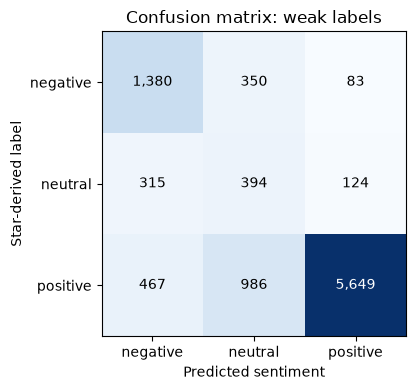

In [4]:
labels = ['negative', 'neutral', 'positive']
report = classification_report(reviews.weak_label, predicted, labels=labels, output_dict=True, zero_division=0)
matrix = confusion_matrix(reviews.weak_label, predicted, labels=labels)
metrics = pd.DataFrame(report).T.loc[labels + ['macro avg', 'weighted avg'], ['precision', 'recall', 'f1-score', 'support']]
display(metrics.round(3))
print(f"Accuracy (star-label agreement): {accuracy_score(reviews.weak_label, predicted):.4f}")
fig, ax = plt.subplots(figsize=(5,4))
ax.imshow(matrix, cmap='Blues')
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{matrix[i,j]:,}', ha='center', va='center', color='white' if matrix[i,j] > matrix.max()/2 else 'black')
ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
       xlabel='Predicted sentiment', ylabel='Star-derived label', title='Confusion matrix: weak labels')
plt.tight_layout(); plt.show()

## Interpretation

Class imbalance, truncation, and clothing-to-electronics domain shift limit these weak-label results. Independent human labels are needed for sentiment accuracy.